In [1]:
from sklearn.metrics import (

    root_mean_squared_error, 
    mean_squared_error, 
    mean_absolute_error,
    mean_absolute_percentage_error,
    max_error,
    r2_score
)
import pandas as pd
import numpy as np

y_test = pd.read_csv("../data/y_test.csv")
predict_dtr = pd.read_csv("../data/predict_dtr.csv")
predict_hgbr = pd.read_csv("../data/predict_hgbr.csv")
predict_xgbr = pd.read_csv("../data/predict_xgbr.csv")
predict_lgbm = pd.read_csv("../data/predict_lgbm.csv")
predict_dtr_hypertuned = pd.read_csv("../data/predict_dtr_hypertuned.csv")
predict_hgbr_hypertuned = pd.read_csv("../data/predict_hgbr_hypertuned.csv")
predict_xgbr_hypertuned = pd.read_csv("../data/predict_xgbr_hypertuned.csv")
predict_lgbm_hypertuned = pd.read_csv("../data/predict_lgbm_hypertuned.csv")

models = {
    "Decision Tree Regressor": predict_dtr,
    "HistGradient Boosting Regressor": predict_hgbr,
    "XGBoost Regressor": predict_xgbr,
    "LGBM Regressor": predict_lgbm
}

hypertuned_models = {
    "Decision Tree Regressor": predict_dtr_hypertuned,
    "HistoGradient Boosting Regressor": predict_hgbr_hypertuned,
    "XGBoost Regressor": predict_xgbr_hypertuned,
    "LGBM Regressor": predict_lgbm_hypertuned
}

evaluation_results = []
evaluation_results_hypertuned = []


for model_name, prediction in models.items():
    rmse = root_mean_squared_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    mape = mean_absolute_percentage_error(y_test, prediction)
    me = max_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)
    
    evaluation_results.append([
        model_name,
        rmse,
        mse,
        mae,
        mape,
        me,
        r2
    ])
    
for model_name, prediction in hypertuned_models.items():
    rmse = root_mean_squared_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    mape = mean_absolute_percentage_error(y_test, prediction)
    me = max_error(y_test, prediction)
    r2 = r2_score(y_test, prediction)
    
    evaluation_results_hypertuned.append([
        model_name,
        rmse,
        mse,
        mae,
        mape,
        me,
        r2
    ])
    


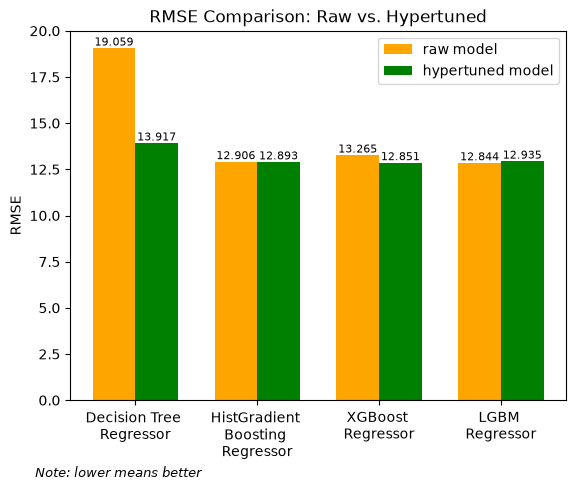

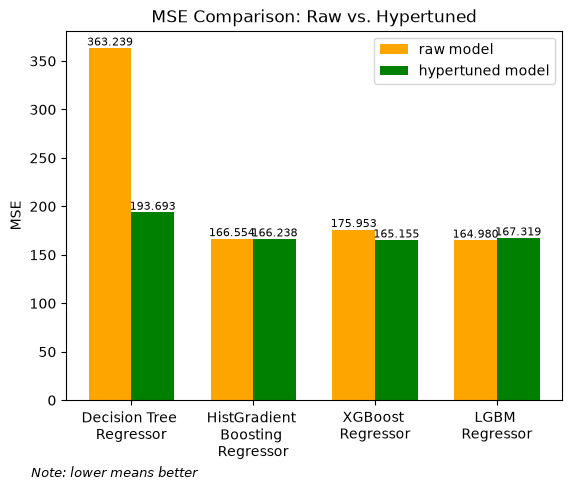

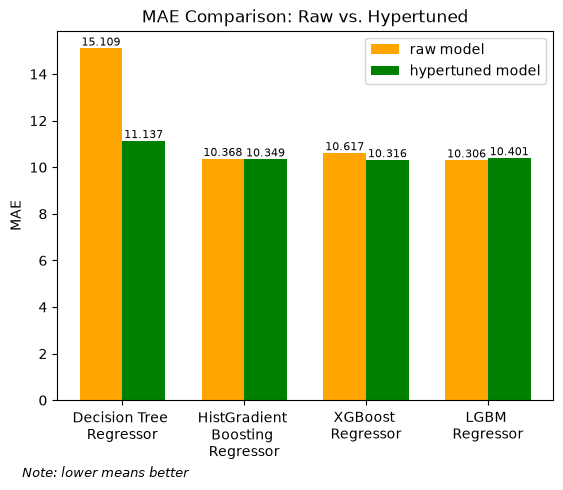

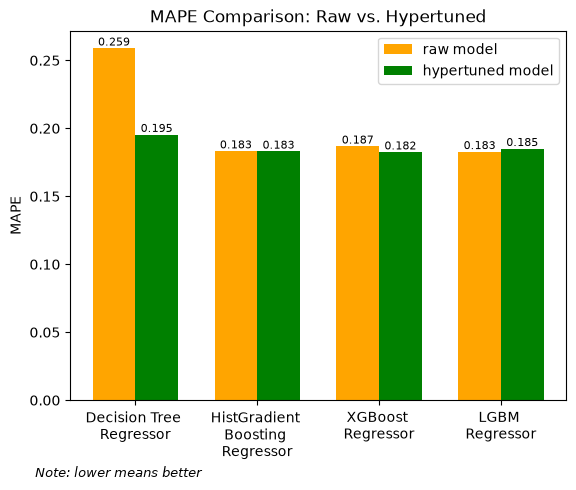

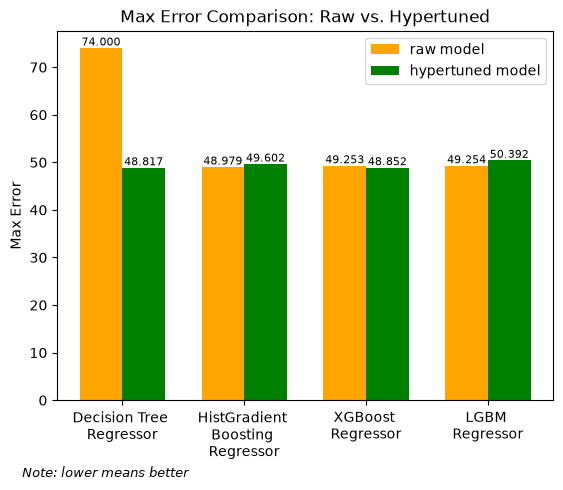

In [2]:
import matplotlib.pyplot as plt

model_names = ["Decision Tree \nRegressor",
               "HistGradient \nBoosting \nRegressor",
               "XGBoost \nRegressor",
               "LGBM \nRegressor"]

metrics = ["RMSE", "MSE", "MAE", "MAPE", "Max Error"]

metric_map = {
    "RMSE": 1,
    "MSE": 2,
    "MAE": 3,
    "MAPE": 4,
    "Max Error": 5,
}

x = np.arange(len(model_names))
width = 0.35

for metric in metrics:

    idx = metric_map[metric]
    raw_metric = [row[idx] for row in evaluation_results]
    hypertuned_metric = [row[idx] for row in evaluation_results_hypertuned]

    raw_bar = plt.bar(
        x - width/2,
        raw_metric,
        width=width,
        color="orange",
        label="raw model"
    )

    hypertuned_bar = plt.bar(
        x + width/2,
        hypertuned_metric,
        width=width,
        color="green",
        label="hypertuned model"
    )

    if metric == "MAPE":
        fmt = "%.3f"
    else:
        fmt = "%.3f"

    plt.bar_label(raw_bar, fmt=fmt, fontsize=8)
    plt.bar_label(hypertuned_bar, fmt=fmt, fontsize=8)

    plt.xticks(
        x,
        model_names,
    )

    plt.ylabel(metric)
    plt.title(f"{metric} Comparison: Raw vs. Hypertuned")
    plt.legend(loc="upper right")

    plt.figtext(
        0.2,
        -0.05,
        "Note: lower means better",
        ha="center",
        fontsize=9,
        style="italic",
    )

    plt.show()

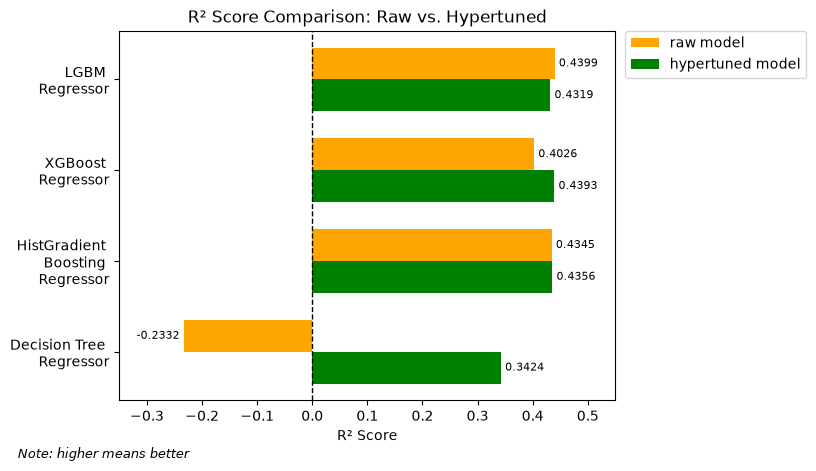

In [3]:
import matplotlib.pyplot as plt

model_names = ["Decision Tree \nRegressor",
            "HistGradient \nBoosting \nRegressor",
            "XGBoost \nRegressor",
            "LGBM \nRegressor"]

raw_r2 = [row[6] for row in evaluation_results]
hypertuned_r2 = [row[6] for row in evaluation_results_hypertuned]

y = np.arange(len(model_names))

height = 0.35



raw_bar = plt.barh(
    y + height/2,
    raw_r2,
    height=height,
    color="orange",
    label="raw model"
)

hypertuned_bar = plt.barh(
    y - height/2,
    hypertuned_r2,
    height=height,
    color="green",
    label="hypertuned model"
)

plt.bar_label(raw_bar, fmt="%.4f", fontsize=8, padding=3)
plt.bar_label(hypertuned_bar, fmt="%.4f", fontsize=8, padding=3)


plt.yticks(
    y,
    model_names,  
)

plt.axvline(0, color="black", linestyle="--", linewidth=1)

plt.xlabel("R² Score")
plt.title("R² Score Comparison: Raw vs. Hypertuned")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.xlim(-0.35, 0.55)

plt.figtext(
    0.1, 
    -0.01, 
    "Note: higher means better",
    ha="center",
    fontsize=9,
    style="italic",
)
  # Keeps standard width, sets height to 8

plt.show()


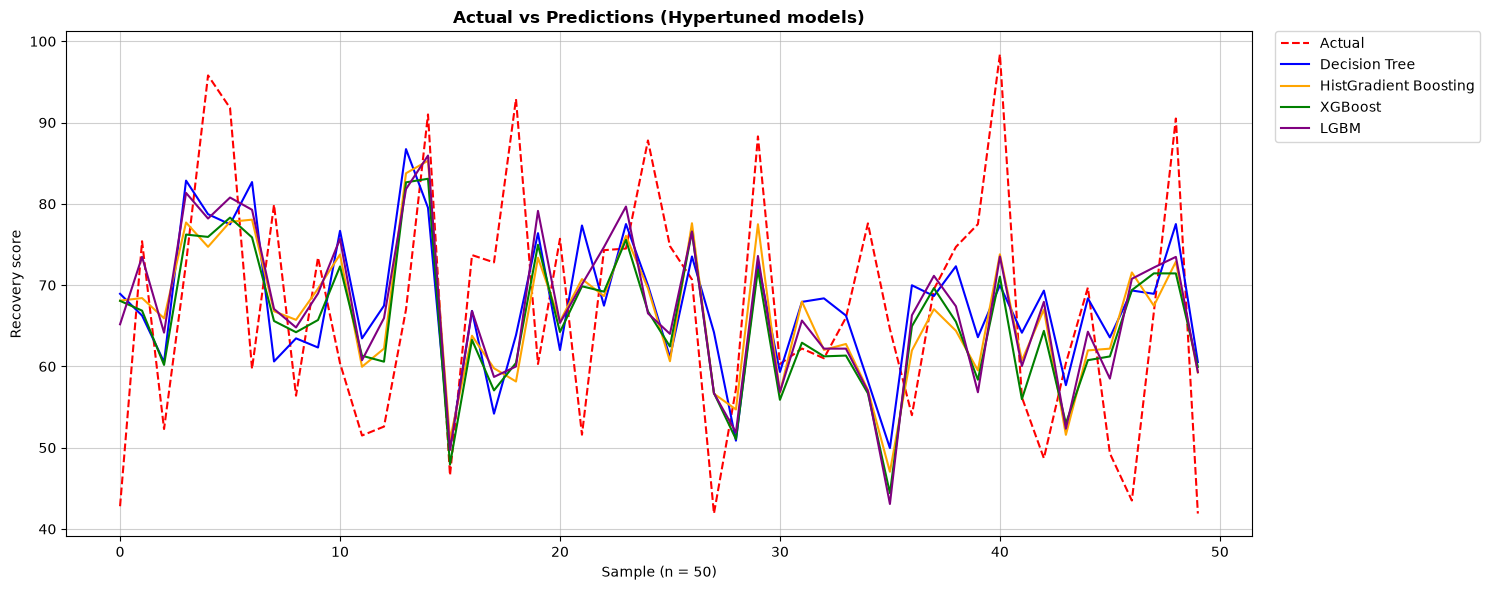

In [4]:
import matplotlib.pyplot as plt

sample_size = 50

plt.figure(figsize=(15, 6))

plt.plot(
    y_test.iloc[:sample_size].values,
    label="Actual",
    color="red",
    linestyle="--",
)
plt.plot(
    predict_dtr_hypertuned[:sample_size], label="Decision Tree", color="blue", linewidth=1.5
)
plt.plot(
    predict_hgbr_hypertuned[:sample_size],
    label="HistGradient Boosting",
    color="orange",
    linewidth=1.5,
)
plt.plot(
    predict_xgbr_hypertuned[:sample_size], label="XGBoost", color="green", linewidth=1.5
)
plt.plot(
    predict_lgbm_hypertuned[:sample_size], label="LGBM", color="purple", linewidth=1.5
)

plt.title("Actual vs Predictions (Hypertuned models)", fontsize=12, fontweight="bold")
plt.xlabel(f"Sample (n = {sample_size})", fontsize=10)
plt.ylabel("Recovery score", fontsize=10)

plt.grid(True, linestyle="-", alpha=0.6)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

plt.tight_layout()
plt.show()

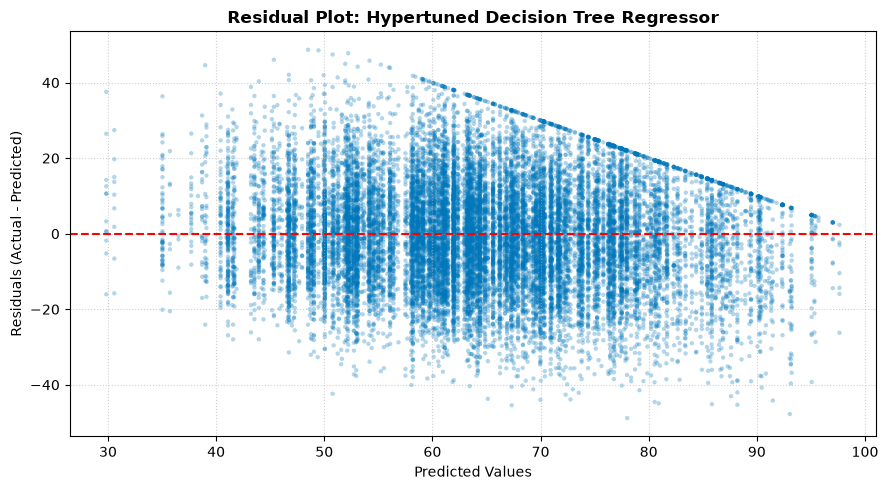

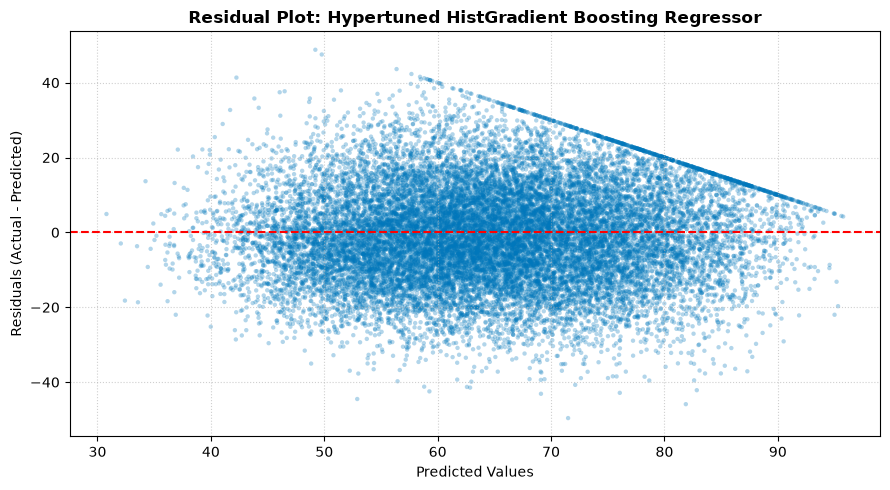

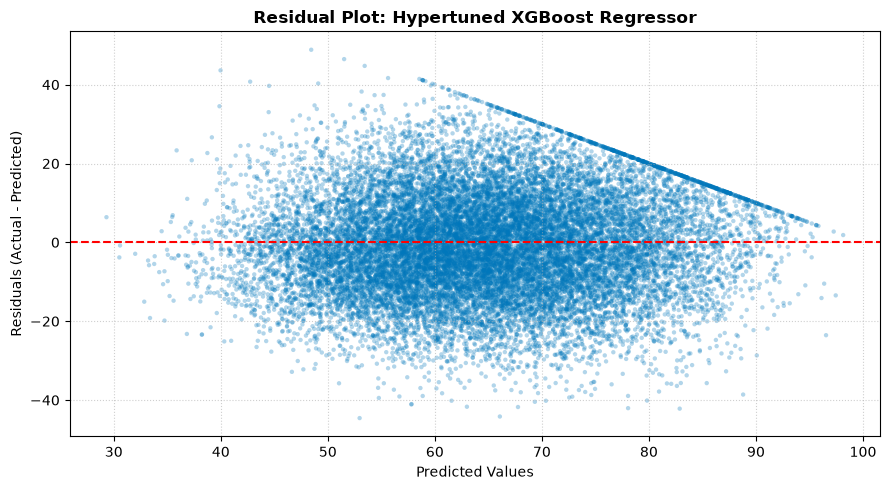

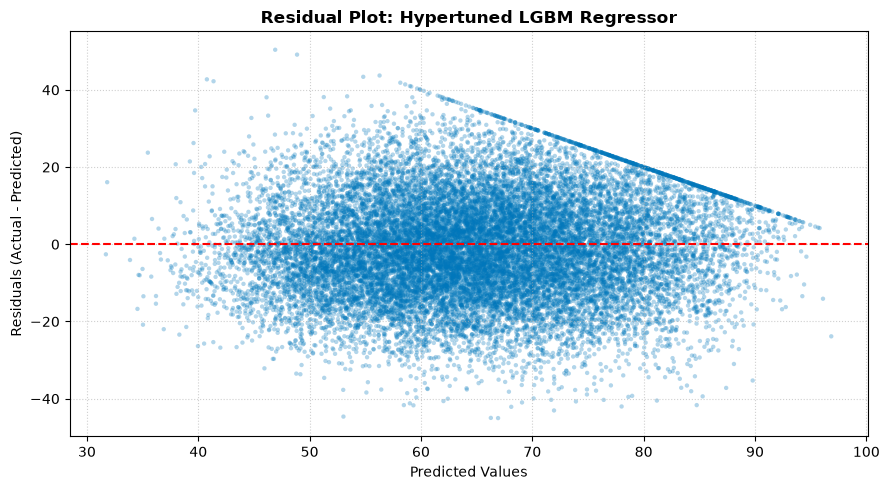

In [5]:
import matplotlib.pyplot as plt
import numpy as np

models = {
    "Decision Tree Regressor": predict_dtr_hypertuned,
    "HistGradient Boosting Regressor": predict_hgbr_hypertuned,
    "XGBoost Regressor": predict_xgbr_hypertuned,
    "LGBM Regressor": predict_lgbm_hypertuned,
}

for name, predictions in models.items():
    y_true = np.asarray(y_test).flatten()
    y_pred = np.asarray(predictions).flatten()

    residuals = y_true - y_pred

    plt.figure(figsize=(9, 5))

    plt.scatter(
        y_pred, residuals, alpha=0.3, color="#0077BB", edgecolors="none", s=10
    )

    plt.axhline(0, color="red", linestyle="--", linewidth=1.5)

    plt.title(f"Residual Plot: Hypertuned {name}", fontsize=12, fontweight="bold")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()